# Phase 2 | GMM vs. Autoencoder Fraud Triage

Compare the saved full-covariance GMM (10 components) and standard autoencoder (12 latent dimensions) with a validation-selected blend. Larger anomaly scores rank first. The validation split determines score normalization, the blend weight, and the false-positive budgets. The chronological held-out test split measures ranking, queue yield, and fraud overlap.

Run `python -m src.preprocess` from the repository root to produce the required CSVs. This notebook uses the checked-in checkpoints and their original training scalers.

## Saved models and chronological validation split

Both estimators score the same 29 features using their own stored training scaler. The GMM uses negative log likelihood. The autoencoder uses mean squared reconstruction error and runs in CPU inference mode. Only load the repository's trusted model artifacts.

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import (
    average_precision_score, precision_recall_curve, roc_auc_score, roc_curve,
)
from sklearn.preprocessing import StandardScaler

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

from src.autoencoder import FraudAutoencoder
from src.preprocess import FEATURE_COLS, TARGET_COL

model_dir = root / "models"
processed = root / "data" / "processed"
gmm = joblib.load(model_dir / "best_gmm.joblib")
gmm_scaler = joblib.load(model_dir / "scaler.joblib")
ae_scaler = joblib.load(model_dir / "scaler_dedup.joblib")
checkpoint = torch.load(model_dir / "best_autoencoder.pt", map_location="cpu", weights_only=True)
ae = FraudAutoencoder(
    input_dim=len(FEATURE_COLS),
    hidden_dims=checkpoint["hidden_dims"],
    latent_dim=checkpoint["latent_dim"],
    dropout_rate=checkpoint["dropout_rate"],
)
ae.load_state_dict(checkpoint["state_dict"])
ae.eval()
assert gmm.n_components == 10 and gmm.covariance_type == "full"
assert ae.latent_dim == 12


def load_split(name, expected_rows, expected_frauds):
    path = processed / f"{name}.csv"
    if not path.is_file():
        raise FileNotFoundError(f"{path} is missing. Run python -m src.preprocess first.")
    frame = pd.read_csv(path, usecols=[*FEATURE_COLS, TARGET_COL])
    assert len(frame) == expected_rows, f"Unexpected size for {name}"
    assert frame[TARGET_COL].isin([0, 1]).all(), f"Unexpected classes in {name}"
    assert frame[TARGET_COL].sum() == expected_frauds, f"Unexpected fraud count for {name}"
    return frame


def base_scores(frame):
    features = frame[FEATURE_COLS]
    scores = pd.DataFrame({
        "GMM": -gmm.score_samples(gmm_scaler.transform(features)),
        "Autoencoder": ae.reconstruction_errors(ae_scaler.transform(features.to_numpy())),
    }, index=frame.index, dtype=float)
    assert np.isfinite(scores.to_numpy()).all()
    return scores


validation = load_split("val", expected_rows=56_961, expected_frauds=57)
y_val = validation[TARGET_COL].astype(bool)
val_scores = base_scores(validation)
print(f"Validation: {len(y_val):,} rows, {y_val.sum():,} frauds.")

Validation: 56,961 rows, 57 frauds.


## Validation-only blend selection

Fit a per-model z-score transform on all validation scores. Sweep the prespecified GMM weights and select by validation average precision (AP). If AP ties, prefer the weight closest to 0.50, then the smaller weight. Base models were trained on legitimate data. Blend selection uses validation labels.

In [2]:
normalizer = StandardScaler().fit(val_scores)


def normalized(scores):
    return pd.DataFrame(normalizer.transform(scores), index=scores.index, columns=scores.columns)


def blend(z_scores, alpha):
    return alpha * z_scores["GMM"] + (1 - alpha) * z_scores["Autoencoder"]


val_z = normalized(val_scores)
sweep = []
for weight in (0.0, 0.25, 0.5, 0.75, 1.0):
    score = blend(val_z, weight)
    sweep.append((weight, average_precision_score(y_val, score), roc_auc_score(y_val, score)))

validation_ranking = pd.DataFrame(sweep, columns=["GMM weight", "Validation AP", "Validation ROC-AUC"])
alpha, _, _ = max(sweep, key=lambda result: (result[1], -abs(result[0] - 0.5), -result[0]))
val_scores["Hybrid"] = blend(val_z, alpha)

display(validation_ranking.round(6))
print(f"Locked GMM weight: {alpha:.2f}")

,GMM weight,Validation AP,Validation ROC-AUC
0,0.00,0.122193,0.946707
1,0.25,0.154976,0.947561
2,0.50,0.184159,0.945752
3,0.75,0.243651,0.940250
4,1.00,0.478234,0.935078


Locked GMM weight: 1.00


## False-positive budgets and locked cutoffs

With $N_0$ legitimate validation rows and target $b$ basis points, at most $\lfloor bN_0/10000\rfloor$ legitimate rows may be flagged. Sort their scores in descending order and use the first excluded score as the cutoff. Flag with a strict greater-than comparison. A tie at the boundary can leave capacity unused. The same score-space thresholds and comparison rule apply on test.

In [3]:
budgets_bp = (10, 50, 100)
calibration = []
for model in val_scores:
    legit_desc = np.sort(val_scores.loc[~y_val, model].to_numpy())[::-1]
    for budget_bp in budgets_bp:
        allowed = budget_bp * len(legit_desc) // 10_000
        cutoff = legit_desc[allowed]
        val_fp = int(np.count_nonzero(legit_desc > cutoff))
        assert val_fp <= allowed
        calibration.append((model, budget_bp / 100, cutoff, val_fp, 100 * val_fp / len(legit_desc)))

cutoffs = pd.DataFrame(
    calibration,
    columns=["Model", "FPR target (%)", "Cutoff", "Val FP", "Val FPR (%)"],
)
display(cutoffs.round(6))

,Model,FPR target (%),Cutoff,Val FP,Val FPR (%)
0,GMM,0.1,114.749583,56,0.098411
1,GMM,0.5,68.723566,284,0.499086
2,GMM,1.0,60.692267,569,0.999930
3,Autoencoder,0.1,9.780338,56,0.098411
4,Autoencoder,0.5,3.057487,284,0.499086
5,Autoencoder,1.0,2.016608,569,0.999930
6,Hybrid,0.1,0.983374,56,0.098411
7,Hybrid,0.5,0.665640,284,0.499086
8,Hybrid,1.0,0.610197,569,0.999930


## Held-out ranking and operational triage

Load the test stream after fixing all calibration parameters. Average precision summarizes the precision-recall ranking using recall increments as weights. Threshold precision is the fraction of alerts that are fraud, recall is the fraction of test frauds caught, and actual FPR is the fraction of legitimate test rows flagged. Actual test FPR may differ from the validation target.

In [4]:
test = load_split("test", expected_rows=56_962, expected_frauds=75)
y_test = test[TARGET_COL].astype(bool)
test_scores = base_scores(test)
test_scores["Hybrid"] = blend(normalized(test_scores), alpha)

ranking = pd.DataFrame([
    (model, average_precision_score(y_test, score), roc_auc_score(y_test, score))
    for model, score in test_scores.items()
], columns=["Model", "Test AP (PR-AUC)", "Test ROC-AUC"])

operating_rows = []
for model, budget, cutoff, val_fp, val_fpr in cutoffs.itertuples(index=False, name=None):
    flagged = test_scores[model] > cutoff
    tp = int((flagged & y_test).sum())
    fp = int((flagged & ~y_test).sum())
    operating_rows.append((model, budget, tp, fp, 100 * fp / (~y_test).sum(),
                           100 * tp / y_test.sum(), 100 * tp / (tp + fp) if tp + fp else np.nan))

operating = pd.DataFrame(operating_rows, columns=[
    "Model", "FPR target (%)", "TP", "FP", "Actual test FPR (%)", "Recall (%)", "Precision (%)",
])
print(f"Held-out test: {len(y_test):,} rows, {y_test.sum():,} frauds ({100 * y_test.mean():.3f}%).")
display(ranking.round(6))
display(operating.round(4))

Held-out test: 56,962 rows, 75 frauds (0.132%).


,Model,Test AP (PR-AUC),Test ROC-AUC
0,GMM,0.483267,0.910601
1,Autoencoder,0.245274,0.927365
2,Hybrid,0.483267,0.910601


,Model,FPR target (%),TP,FP,Actual test FPR (%),Recall (%),Precision (%)
0,GMM,0.1,57,35,0.0615,76.0000,61.9565
1,GMM,0.5,59,192,0.3375,78.6667,23.5060
2,GMM,1.0,59,346,0.6082,78.6667,14.5679
3,Autoencoder,0.1,22,30,0.0527,29.3333,42.3077
4,Autoencoder,0.5,53,141,0.2479,70.6667,27.3196
5,Autoencoder,1.0,55,346,0.6082,73.3333,13.7157
6,Hybrid,0.1,57,35,0.0615,76.0000,61.9565
7,Hybrid,0.5,59,192,0.3375,78.6667,23.5060
8,Hybrid,1.0,59,346,0.6082,78.6667,14.5679


## Fixed analyst queues

Compare identical review capacity across scores. Sort in descending score order and preserve CSV row order within ties so each queue contains exactly $K$ transactions.

In [5]:
queue_sizes = (50, 100, 200, 500)
ranked_rows = {
    model: score.sort_values(ascending=False, kind="stable").index
    for model, score in test_scores.items()
}
queue = []
for model, rows in ranked_rows.items():
    for k in queue_sizes:
        tp = int(y_test.loc[rows[:k]].sum())
        queue.append((model, k, tp, 100 * tp / k, 100 * tp / y_test.sum()))

queues = pd.DataFrame(queue, columns=["Model", "K", "TP", "Precision@K (%)", "Recall@K (%)"])
display(queues.round(4))

,Model,K,TP,Precision@K (%),Recall@K (%)
0,GMM,50,29,58.0,38.6667
1,GMM,100,57,57.0,76.0000
2,GMM,200,58,29.0,77.3333
3,GMM,500,59,11.8,78.6667
4,Autoencoder,50,20,40.0,26.6667
5,Autoencoder,100,35,35.0,46.6667
6,Autoencoder,200,53,26.5,70.6667
7,Autoencoder,500,59,11.8,78.6667
8,Hybrid,50,29,58.0,38.6667
9,Hybrid,100,57,57.0,76.0000


## Fraud overlap and feature profiles

Row indices are zero-based positions in the processed test CSV, excluding its header. The table partitions all 75 frauds at each operating rule. Feature summaries use the original Amount and signed PCA values (V14, V17, V12). Medians and interquartile ranges describe each group. An empty group has no summary, and groups with few observations support descriptive comparisons only.

In [6]:
frauds = test.index[y_test]
gmm_cutoff, ae_cutoff = (
    cutoffs.loc[(cutoffs["Model"] == model) & (cutoffs["FPR target (%)"] == 0.10), "Cutoff"].item()
    for model in ("GMM", "Autoencoder")
)
rules = {
    "Validation FPR ≤ 0.10%": (
        test.index[test_scores["GMM"] > gmm_cutoff],
        test.index[test_scores["Autoencoder"] > ae_cutoff],
    ),
    "Top 100": (ranked_rows["GMM"][:100], ranked_rows["Autoencoder"][:100]),
}

overlap_rows = []
profile_rows = []
profile_features = ["Amount", "V14", "V17", "V12"]
for rule, (gmm_flags, ae_flags) in rules.items():
    gmm_hits, ae_hits = frauds.isin(gmm_flags), frauds.isin(ae_flags)
    groups = {
        "Both": gmm_hits & ae_hits,
        "GMM only": gmm_hits & ~ae_hits,
        "AE only": ~gmm_hits & ae_hits,
        "Missed by both": ~(gmm_hits | ae_hits),
    }
    assert np.all(np.stack(list(groups.values())).sum(axis=0) == 1)
    for group, mask in groups.items():
        indices = frauds[mask].tolist()
        overlap_rows.append((rule, group, len(indices), indices))
        quantiles = test.loc[indices, profile_features].quantile([0.25, 0.50, 0.75])
        for feature in profile_features:
            q1, median, q3 = quantiles[feature]
            profile_rows.append((rule, group, len(indices), feature, median, q1, q3))

overlap = pd.DataFrame(overlap_rows, columns=["Rule", "Group", "Count", "Test indices"])
profiles = pd.DataFrame(profile_rows, columns=["Rule", "Group", "Count", "Feature", "Median", "Q1", "Q3"])
with pd.option_context("display.max_colwidth", None):
    display(overlap)
display(profiles.round(3))

,Rule,Group,Count,Test indices
0,Validation FPR ≤ 0.10%,Both,22,"[6729, 7771, 7789, 10377, 15548, 15702, 15854, 15904, 16003, 16159, 16488, 21983, 22118, 22916, 24059, 24279, 34715, 34981, 35429, 35479, 36032, 40530]"
1,Validation FPR ≤ 0.10%,GMM only,35,"[1867, 2231, 2631, 5413, 6787, 6788, 6860, 7799, 9262, 10521, 11654, 11656, 13409, 13600, 19828, 20150, 20451, 21126, 21322, 21762, 23632, 24021, 24929, 27558, 27711, 30558, 33211, 33628, 34080, 46630, 49019, 52018, 52298, 52304, 53299]"
2,Validation FPR ≤ 0.10%,AE only,0,[]
3,Validation FPR ≤ 0.10%,Missed by both,18,"[1885, 4133, 9581, 10621, 12377, 17502, 17711, 21394, 24036, 24046, 26499, 26550, 35235, 44676, 46537, 48147, 48226, 53829]"
4,Top 100,Both,35,"[1867, 2231, 2631, 6729, 7771, 7789, 7799, 10377, 13600, 15548, 15702, 15854, 15904, 16003, 16159, 16488, 19828, 21322, 21762, 21983, 22118, 22916, 23632, 24021, 24059, 24279, 24929, 34715, 34981, 35429, 35479, 36032, 40530, 52018, 53299]"
5,Top 100,GMM only,22,"[5413, 6787, 6788, 6860, 9262, 10521, 11654, 11656, 13409, 20150, 20451, 21126, 27558, 27711, 30558, 33211, 33628, 34080, 46630, 49019, 52298, 52304]"
6,Top 100,AE only,0,[]
7,Top 100,Missed by both,18,"[1885, 4133, 9581, 10621, 12377, 17502, 17711, 21394, 24036, 24046, 26499, 26550, 35235, 44676, 46537, 48147, 48226, 53829]"


,Rule,Group,Count,Feature,Median,Q1,Q3
0,Validation FPR ≤ 0.10%,Both,22,Amount,1.000,0.770,3.793
1,Validation FPR ≤ 0.10%,Both,22,V14,-11.930,-13.155,-8.601
2,Validation FPR ≤ 0.10%,Both,22,V17,-5.731,-6.544,-3.517
3,Validation FPR ≤ 0.10%,Both,22,V12,-6.402,-7.929,-5.975
4,Validation FPR ≤ 0.10%,GMM only,35,Amount,10.700,0.975,139.340
5,Validation FPR ≤ 0.10%,GMM only,35,V14,-6.281,-8.486,-4.838
6,Validation FPR ≤ 0.10%,GMM only,35,V17,-2.515,-4.306,-1.379
7,Validation FPR ≤ 0.10%,GMM only,35,V12,-3.805,-4.843,-3.050
8,Validation FPR ≤ 0.10%,AE only,0,Amount,NaN,NaN,NaN
9,Validation FPR ≤ 0.10%,AE only,0,V14,NaN,NaN,NaN


## Held-out precision-recall and ROC curves

The dashed references show test prevalence in the PR panel and chance discrimination in the ROC panel. Curves summarize the test rankings. Operational results use the thresholds fixed above. At the selected endpoint, the dotted hybrid curve lies directly over the solid GMM curve.

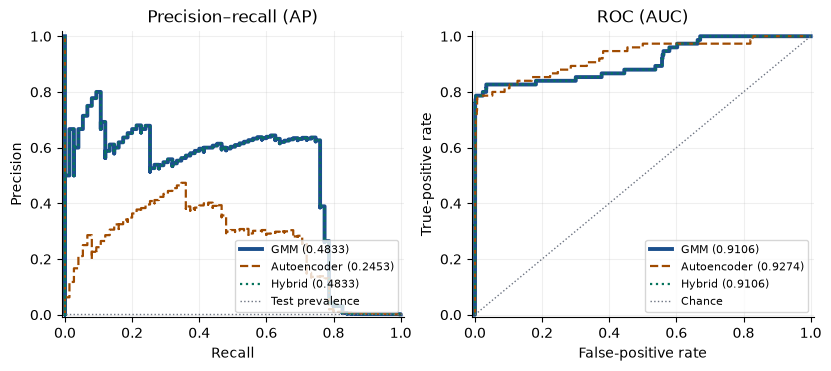

In [7]:
colors = {"GMM": "#1B4F8C", "Autoencoder": "#A04B00", "Hybrid": "#06745D"}
styles = {"GMM": "-", "Autoencoder": "--", "Hybrid": ":"}
figures = root / "docs" / "phase2_dl_ieee" / "figures"
figures.mkdir(parents=True, exist_ok=True)
ranking_by_model = ranking.set_index("Model")

with plt.rc_context({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False}):
    fig, (pr_ax, roc_ax) = plt.subplots(1, 2, figsize=(8.2, 3.6), layout="constrained")
    for model, score in test_scores.items():
        precision, recall, _ = precision_recall_curve(y_test, score)
        fpr, tpr, _ = roc_curve(y_test, score)
        ap, auc = ranking_by_model.loc[model]
        style = {"color": colors[model], "linestyle": styles[model], "lw": 2.8 if model == "GMM" and alpha == 1 else 1.6}
        pr_ax.step(recall[::-1], precision[::-1], where="pre", label=f"{model} ({ap:.4f})", **style)
        roc_ax.plot(fpr, tpr, label=f"{model} ({auc:.4f})", **style)
    pr_ax.axhline(y_test.mean(), color="#6B7280", lw=1, ls=":", label="Test prevalence")
    roc_ax.plot([0, 1], [0, 1], color="#6B7280", lw=1, ls=":", label="Chance")
    pr_ax.set(title="Precision–recall (AP)", xlabel="Recall", ylabel="Precision")
    roc_ax.set(title="ROC (AUC)", xlabel="False-positive rate", ylabel="True-positive rate")
    for ax in (pr_ax, roc_ax):
        ax.set(xlim=(-0.01, 1.01), ylim=(-0.01, 1.02))
        ax.grid(alpha=0.2)
        ax.legend(loc="lower right", fontsize=8)
    fig.savefig(figures / "test_curves.pdf", bbox_inches="tight")
    plt.show()

## Interpretation

Validation AP selected α = 1.00. The resulting hybrid is a positive affine transform of the GMM score and yields identical rankings, operating decisions, and queue yields on this split. The autoencoder has the higher ROC-AUC (0.9274 vs. 0.9106). GMM leads in average precision (0.4833 vs. 0.2453) and catches more frauds in the first 50, 100, and 200 reviews. Both catch 59 frauds in the first 500 reviews.

At both the 0.10% validation budget and Top 100, every AE hit is also a GMM hit. The same 18 frauds are missed by both models under either rule. At the validation cutoff, the GMM-only group has more negative median V14, V17, and V12 than the shared misses (−6.28, −2.52, −3.81 vs. −1.89, +1.33, −0.17). Top 100 shows the same direction. Median Amount for GMM-only hits is 10.70 at the cutoff and 7.13 in the queue, compared with 7.80 for shared misses. The Amount interquartile ranges overlap. Neither rule produced an AE-only fraud group for comparison.

These results describe one held-out time window with 75 frauds. The validation FPR budget controls the validation false-alert count. Realized FPR can change in a later stream.